# ARTI 403 – Image Processing
## Lab 6: Frequency Domain Filtering

**Student Name:** Abdulelah Alshammari  
**Student ID:** 2240005261

**Images:** taken from the scikit-image general-purpose dataset (`skimage.data`, see [gallery](https://scikit-image.org/docs/stable/auto_examples/data/plot_general.html)) and saved in the `Images/` folder.
- `camera.png` – the Cameraman image required by the manual (procedural task and assessment task 1)
- `page.png` – a scanned book page, used as an additional example for the Sobel filter

## 0. Setup – import libraries and save the images to `Images/`

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy.ndimage import convolve
from skimage import data, io
from skimage.transform import resize

os.makedirs('Images', exist_ok=True)
io.imsave('Images/camera.png', data.camera(), check_contrast=False)
io.imsave('Images/page.png', data.page(), check_contrast=False)
print(sorted(os.listdir('Images')))

['camera.png', 'page.png']


## 1. Procedural Task – Laplacian Filtering in the Frequency Domain
The Laplacian in the frequency domain is

**H(u, v) = −4π² (u² + v²)**

so filtering is just a multiplication: **G(u, v) = H(u, v) · F(u, v)**, followed by the inverse FFT.

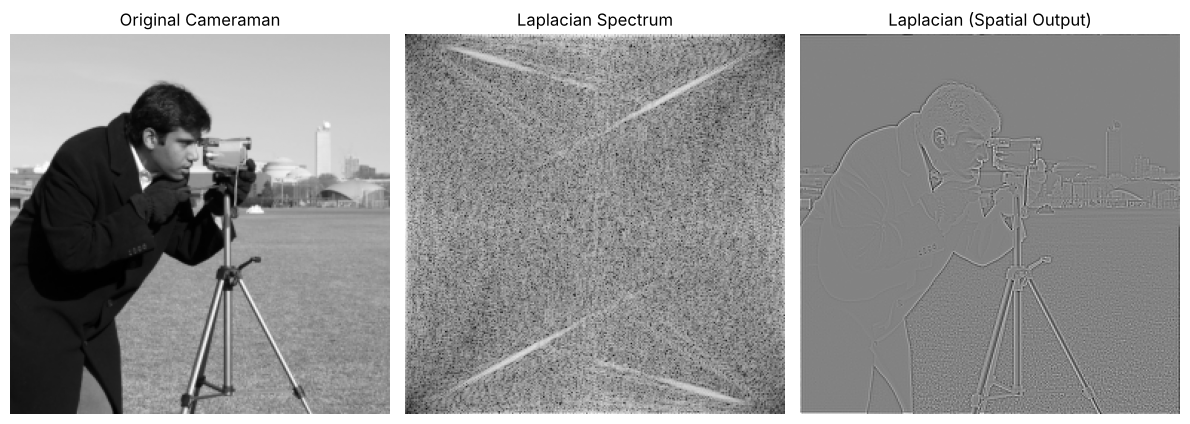

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))   # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

**Observation:** the Laplacian filter is zero at the centre frequency (u = v = 0) and grows with distance from it, so it is a high-pass filter. The low frequencies (smooth sky and coat) are removed, and the spatial output keeps only the edges: the outline of the man, the tripod and the buildings.

# Assessment
## Task 1 – Sobel filters in the frequency domain (Cameraman)

**Steps:**
1. Load and resize the image.
2. Define the Sobel kernels **sobel_x** (vertical edges) and **sobel_y** (horizontal edges).
3. Zero-pad each 3×3 kernel to the image size with its centre at the image centre, then `ifftshift` it so the kernel centre moves to (0, 0) before the FFT. Without this shift the output would be translated.
4. Compute the FFT of the image.
5. Multiply in the frequency domain: **Gx = F · Hx**, **Gy = F · Hy**, then inverse FFT.
6. Combine the two directions into the gradient magnitude **|G| = √(gx² + gy²)**.

In [3]:
# 1. Load and resize image
image = resize(data.camera(), (256, 256))

# 2. Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# 3. Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))   # Shift before FFT to place (0,0) at top-left

# 4. Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

# 5. Multiply in the frequency domain, then inverse FFT
Gx = F * Hx
Gy = F * Hy
gx = np.real(ifft2(Gx))
gy = np.real(ifft2(Gy))

# 6. Gradient magnitude
magnitude = np.sqrt(gx**2 + gy**2)

print('Image size:', image.shape)
print('gx range: [%.3f, %.3f]' % (gx.min(), gx.max()))
print('gy range: [%.3f, %.3f]' % (gy.min(), gy.max()))
print('magnitude max: %.3f' % magnitude.max())

Image size: (256, 256)
gx range: [-3.180, 3.303]
gy range: [-2.979, 2.665]
magnitude max: 3.448


### Frequency response of the Sobel filters
`fftshift` moves the zero frequency to the centre of each plot.

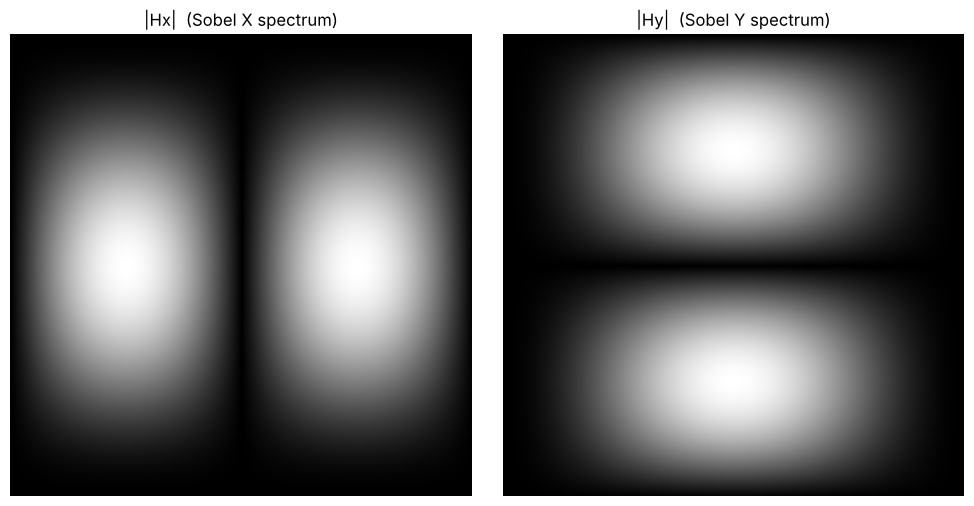

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.abs(fftshift(Hx)), cmap='gray'); ax[0].set_title('|Hx|  (Sobel X spectrum)')
ax[1].imshow(np.abs(fftshift(Hy)), cmap='gray'); ax[1].set_title('|Hy|  (Sobel Y spectrum)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Observation:** |Hx| is zero along the vertical line through the centre (it ignores intensity changes in the vertical direction) and is largest for horizontal frequencies. |Hy| is the same pattern rotated by 90°. Both are zero at the centre, so like the Laplacian they remove the DC component and act as high-pass (derivative) filters.

### Results

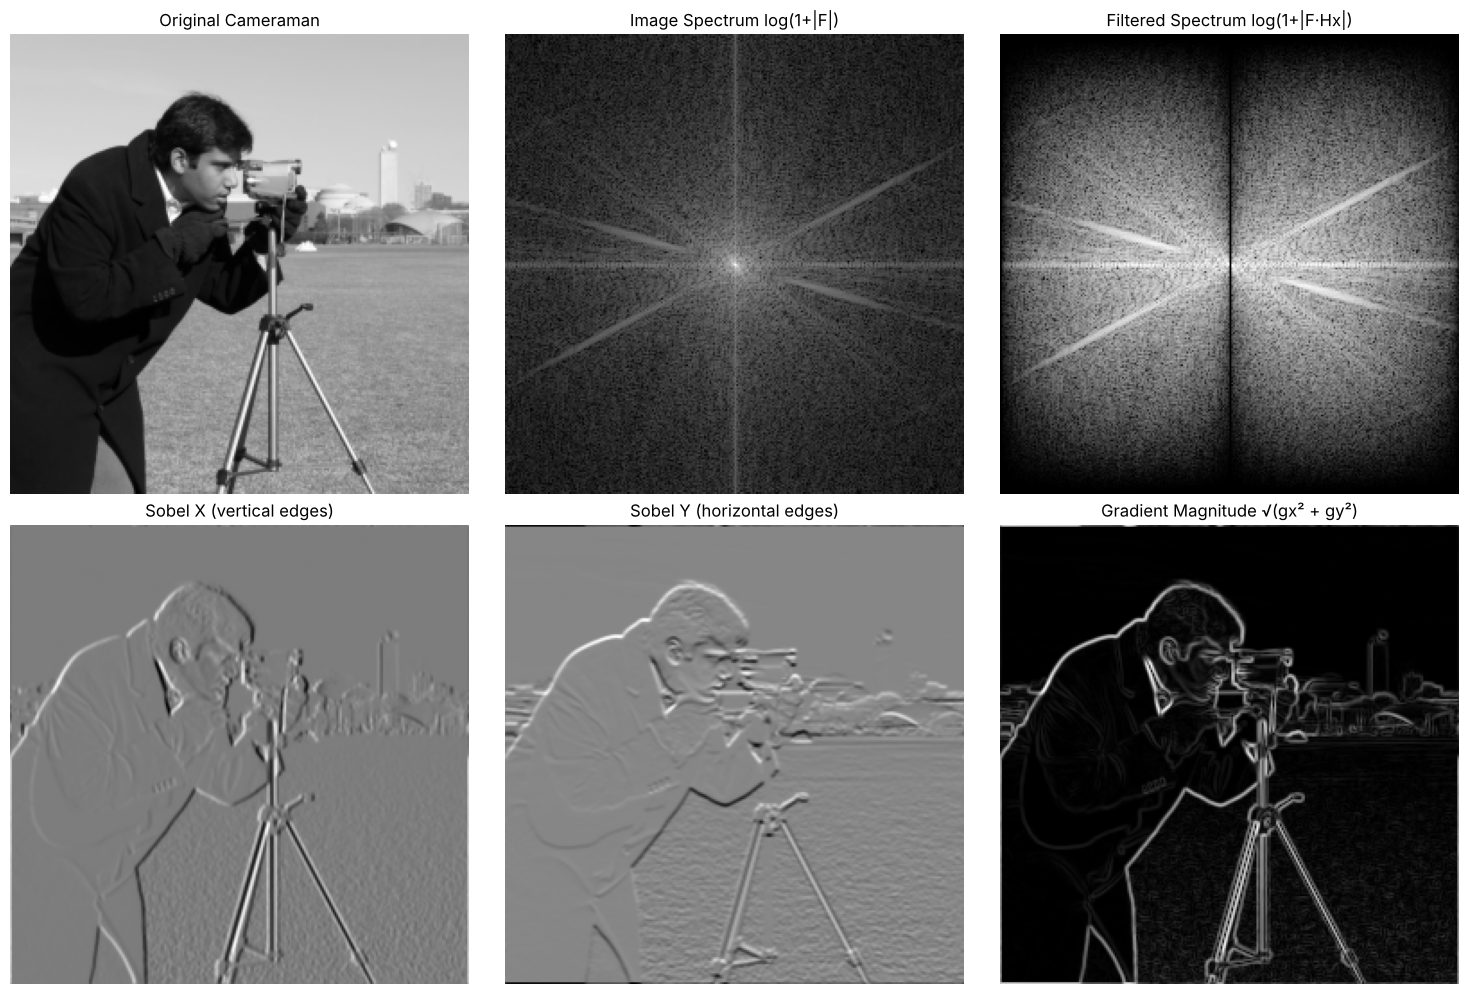

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0, 0].imshow(image, cmap='gray');                       ax[0, 0].set_title('Original Cameraman')
ax[0, 1].imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray'); ax[0, 1].set_title('Image Spectrum log(1+|F|)')
ax[0, 2].imshow(np.log(1 + np.abs(fftshift(Gx))), cmap='gray'); ax[0, 2].set_title('Filtered Spectrum log(1+|F·Hx|)')

ax[1, 0].imshow(gx, cmap='gray');        ax[1, 0].set_title('Sobel X (vertical edges)')
ax[1, 1].imshow(gy, cmap='gray');        ax[1, 1].set_title('Sobel Y (horizontal edges)')
ax[1, 2].imshow(magnitude, cmap='gray'); ax[1, 2].set_title('Gradient Magnitude √(gx² + gy²)')

for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

**Observation:** Sobel X highlights vertical edges (the tripod legs, the man's back and the building sides), while Sobel Y highlights horizontal edges (the horizon line, the camera top). The gradient magnitude combines both, giving a complete edge map of the image.

### Verification – frequency domain vs. spatial domain
By the **convolution theorem**, multiplying the FFTs is the same as a circular convolution in the spatial domain. So the result should match `scipy.ndimage.convolve` with `mode='wrap'` (wrap = circular boundary, which is what the FFT assumes).

In [6]:
gx_spatial = convolve(image, sobel_x, mode='wrap')
gy_spatial = convolve(image, sobel_y, mode='wrap')

print('Max |difference| Sobel X:', np.abs(gx - gx_spatial).max())
print('Max |difference| Sobel Y:', np.abs(gy - gy_spatial).max())
print('Same result:', np.allclose(gx, gx_spatial) and np.allclose(gy, gy_spatial))

Max |difference| Sobel X: 1.4883927423881005e-15
Max |difference| Sobel Y: 2.8380076066980564e-15
Same result: True


**Observation:** the differences are at floating-point level (≈1e-15), so filtering in the frequency domain gives exactly the same result as spatial convolution. This also confirms the kernel was centred correctly with `ifftshift`.

## Additional Example – Sobel in the frequency domain on a scanned page
The same function is applied to the `page` image from scikit-image (a scanned book page). The image is not square, which shows the method works for any image size.

Page size: (191, 384)


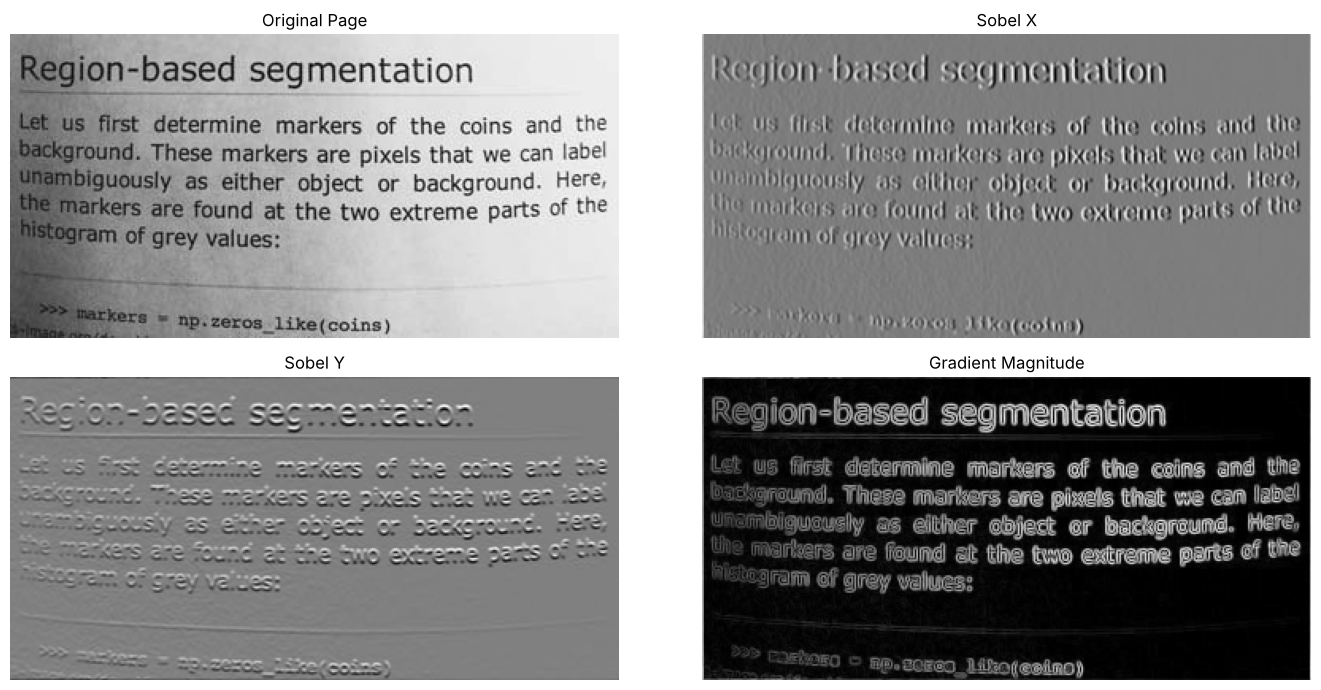

In [7]:
page = data.page() / 255.0
P = fft2(page)
px = np.real(ifft2(P * center_embed_kernel(sobel_x, page.shape)))
py = np.real(ifft2(P * center_embed_kernel(sobel_y, page.shape)))
page_mag = np.sqrt(px**2 + py**2)

print('Page size:', page.shape)
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
ax[0, 0].imshow(page, cmap='gray');     ax[0, 0].set_title('Original Page')
ax[0, 1].imshow(px, cmap='gray');       ax[0, 1].set_title('Sobel X')
ax[1, 0].imshow(py, cmap='gray');       ax[1, 0].set_title('Sobel Y')
ax[1, 1].imshow(page_mag, cmap='gray'); ax[1, 1].set_title('Gradient Magnitude')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the edges of every letter stand out in the gradient magnitude, while the uneven background lighting of the scan (a low-frequency component) is removed.

## Conclusion
- In the frequency domain, filtering is a **multiplication** of the image spectrum with the filter's frequency response, instead of a convolution.
- The **Laplacian** and **Sobel** filters are both high-pass filters: they are zero at the centre frequency and keep the edges.
- A small spatial kernel such as Sobel can be used in the frequency domain by **zero-padding it to the image size and centring it with `ifftshift`**. The result is identical to circular spatial convolution, as the verification step showed.